### Building A Basic Chatbot With Langraph API

In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

graph_builder=StateGraph(State)

In [3]:
graph_builder

In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-120b")

In [6]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001DC3F5263C0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001DC3F526CF0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
## Mnode funcationality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [8]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot", END)

## compile the graph
graph=graph_builder.compile()

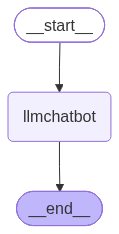

In [9]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [10]:
graph.invoke({"messages":"Hi"})

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='9bf10c71-abeb-42c4-99a4-dcf3b2fd5812'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi". We can just greet back. No special instructions. Provide friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 72, 'total_tokens': 116, 'completion_time': 0.091464178, 'completion_tokens_details': {'reasoning_tokens': 26}, 'prompt_time': 0.003270406, 'prompt_tokens_details': None, 'queue_time': 0.250613018, 'total_time': 0.094734584}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e5b4e54fbb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a207cf-7c0b-77ec-9c94-294f64649ef8-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 44, 'total_tokens': 116, 'output_

In [11]:
from langchain_core.messages import HumanMessage

for event in graph.stream({"messages": [HumanMessage(content="Hi How are you?")]}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I’m doing great, thank you for asking. How can I assist you today?


### Chatbot With Tools

In [12]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("what is langgraph")

{'query': 'what is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://huggingface.co/learn/agents-course/en/unit2/langgraph/when_to_use_langgraph',
   'title': 'What is LangGraph ? · Hugging Face',
   'content': "In essence, whenever possible, as a human, design a flow of actions based on the output of each action, and decide what to execute next accordingly. In this case, LangGraph is the correct framework for you!\n\n`LangGraph` is, in my opinion, the most production-ready agent framework on the market.\n\n`LangGraph`\n\n## How does LangGraph work?\n\nAt its core, `LangGraph` uses a directed graph structure to define the flow of your application:\n\n`LangGraph` [...] Hugging Face's logo\n\nAgents Course documentation\n\nWhat is LangGraph ?\n\n# Agents Course\n\nHugging Face's logo\n\nand get access to the augmented documentation experience\n\nto get started\n\n# What is LangGraph ?\n\n`LangGraph` is a framework developed by LangCha

In [13]:
## Custom function
def multiply(a: int, b: int) -> int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a * b


In [14]:
tools=[tool,multiply]

In [15]:
llm_with_tool=llm.bind_tools(tools)

In [17]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001DC3F5263C0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001DC3F526CF0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for 

In [18]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]


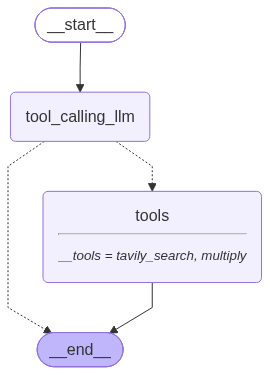

In [20]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", END)

## Compile
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [22]:
response = graph.invoke({
    "messages": [("user", "what is the recent ai news")]
})


In [23]:
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

what is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_0448fb21-bf59-411e-87c8-04deeef6357f)
 Call ID: fc_0448fb21-bf59-411e-87c8-04deeef6357f
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=IGgFXVsHA18", "title": "Government set to declare AI a major 'national security challenge' | 9 News Australia", "content": "# Government set to declare AI a major 'national security challenge' | 9 News Australia\n## Channel: 9 News Australia (verified)\n1.91M subscribers\n17 likes\n\n### Description\n1,054 views\nPosted: 2026-11-22\nThe 

In [24]:
response = graph.invoke({
    "messages": [("user", "what is 2 multiplied  by 3")]
})

In [26]:
response
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

what is 2 multiplied  by 3
================================== Ai Message ==================================

2 × 3 = 6.


In [27]:
response = graph.invoke({
    "messages": [("user", "what is 2 multiplied  by 3 and then multiply by 10")]
})
response
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

what is 2 multiplied  by 3 and then multiply by 10
================================== Ai Message ==================================

\(2 \times 3 = 6\)

\(6 \times 10 = 60\)

So the result is **60**.


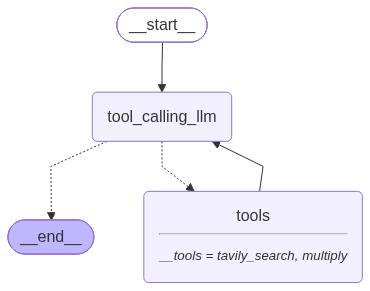

In [28]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")

## Compile
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [29]:
response = graph.invoke({
    "messages": [("user", "what is the recent ai news and then 2 multiply by 10")]
})
response
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

what is the recent ai news and then 2 multiply by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_62c7dd8c-ad70-4c67-98e6-040a98c3c5be)
 Call ID: fc_62c7dd8c-ad70-4c67-98e6-040a98c3c5be
  Args:
    query: AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=IeFDTftW2tA", "title": "AI News - Mid-November 2026", "content": "# AI News - Mid-November 2026\n## Channel: The Enterprise AI Show\n7.49K subscribers\n0 likes [...] ### Description\n1 view\nPosted: 2026-11-14 [...] [45:28] He can just come on over Brian: Just get a microphone. We'd love to have you. All right.\n[45:32] Wit